In [2]:
import pandas as pd
import numpy as np
import mysql.connector

import plotly.express as px
import plotly.graph_objects as go

import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display, HTML
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
DARK_BG = "#0b1120"
CARD_BG = "#111827"
BORDER_COLOR = "#263449"
TEXT_COLOR = "#f8fafc"
MUTED_COLOR = "#94a3b8"

plt.rcParams.update({
    "figure.facecolor": CARD_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": BORDER_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "text.color": TEXT_COLOR,
    "grid.color": BORDER_COLOR,
    "font.family": "DejaVu Sans"
})

print("Dashboard theme configured!")

Dashboard theme configured!


In [5]:
DB_CONFIG = {
    "host": "localhost",
    "user": "root",
    "password": "Saxena@123",
    "database": "traffic_db"
}

try:
    conn = mysql.connector.connect(**DB_CONFIG)

    if conn.is_connected():
        print("Successfully connected to MySQL!")
        print("Database: traffic_db")

except mysql.connector.Error as e:
    print("Database connection failed:", e)

Successfully connected to MySQL!
Database: traffic_db


In [6]:
query = """
SELECT
    id,
    timestamp,
    latitude,
    longitude,
    vehicle_count,
    traffic_speed_kmh,
    road_occupancy_pct,
    traffic_light_state,
    weather_condition,
    accident_report,
    sentiment_score,
    ride_sharing_demand,
    parking_availability,
    emission_levels_g_km,
    energy_consumption_l_h,
    traffic_condition
FROM traffic_data;
"""

df = pd.read_sql(query, conn)

conn.close()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 16)


,id,timestamp,latitude,longitude,vehicle_count,traffic_speed_kmh,road_occupancy_pct,traffic_light_state,weather_condition,accident_report,sentiment_score,ride_sharing_demand,parking_availability,emission_levels_g_km,energy_consumption_l_h,traffic_condition
0,1,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893,82.653,Yellow,Clear,0,-0.60920,2,45,450.760,19.574,High
1,2,2024-03-01 00:05:00,40.831119,-73.987354,202,22.384,45.829,Green,Clear,0,0.96544,16,1,321.800,5.386,High
2,3,2024-03-01 00:10:00,40.819549,-73.732462,252,46.890,82.772,Green,Rain,0,0.28966,16,49,231.153,10.277,High
3,4,2024-03-01 00:15:00,40.725849,-73.980134,37,5.731,37.696,Red,Fog,0,-0.27196,66,10,410.384,29.243,High
4,5,2024-03-01 00:20:00,40.813265,-73.961630,64,61.348,22.313,Red,Snow,0,-0.79761,3,5,364.466,16.801,Low


In [7]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    "latitude",
    "longitude",
    "vehicle_count",
    "traffic_speed_kmh",
    "road_occupancy_pct",
    "accident_report",
    "sentiment_score",
    "ride_sharing_demand",
    "parking_availability",
    "emission_levels_g_km",
    "energy_consumption_l_h"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows without a valid timestamp
df = df.dropna(subset=["timestamp"])

# Create time-related columns
df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.day_name()
df["month"] = df["timestamp"].dt.strftime("%b")

# Reset index
df = df.reset_index(drop=True)

print("Data preparation completed!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Data preparation completed!
Rows: 10000
Columns: 20


,id,timestamp,latitude,longitude,vehicle_count,traffic_speed_kmh,road_occupancy_pct,traffic_light_state,weather_condition,accident_report,sentiment_score,ride_sharing_demand,parking_availability,emission_levels_g_km,energy_consumption_l_h,traffic_condition,date,hour,day,month
0,1,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893,82.653,Yellow,Clear,0,-0.60920,2,45,450.760,19.574,High,2024-03-01,0,Friday,Mar
1,2,2024-03-01 00:05:00,40.831119,-73.987354,202,22.384,45.829,Green,Clear,0,0.96544,16,1,321.800,5.386,High,2024-03-01,0,Friday,Mar
2,3,2024-03-01 00:10:00,40.819549,-73.732462,252,46.890,82.772,Green,Rain,0,0.28966,16,49,231.153,10.277,High,2024-03-01,0,Friday,Mar
3,4,2024-03-01 00:15:00,40.725849,-73.980134,37,5.731,37.696,Red,Fog,0,-0.27196,66,10,410.384,29.243,High,2024-03-01,0,Friday,Mar
4,5,2024-03-01 00:20:00,40.813265,-73.961630,64,61.348,22.313,Red,Snow,0,-0.79761,3,5,364.466,16.801,Low,2024-03-01,0,Friday,Mar


In [8]:
print("DATASET INFORMATION")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Data Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
missing = df.isnull().sum().to_frame("Missing Values")
missing["Missing Percentage"] = (
    missing["Missing Values"] / len(df) * 100
).round(2)

display(missing)

print("\nNumerical Summary:")
display(df.describe().round(2))

DATASET INFORMATION

Dataset Shape:
(10000, 20)

Column Data Types:


,Data Type
id,int64
timestamp,datetime64[ns]
latitude,float64
longitude,float64
vehicle_count,int64
traffic_speed_kmh,float64
road_occupancy_pct,float64
traffic_light_state,object
weather_condition,object
accident_report,int64



Missing Values:


,Missing Values,Missing Percentage
id,0,0.0
timestamp,0,0.0
latitude,0,0.0
longitude,0,0.0
vehicle_count,0,0.0
traffic_speed_kmh,0,0.0
road_occupancy_pct,0,0.0
traffic_light_state,0,0.0
weather_condition,0,0.0
accident_report,0,0.0



Numerical Summary:


,id,timestamp,latitude,longitude,vehicle_count,traffic_speed_kmh,road_occupancy_pct,accident_report,sentiment_score,ride_sharing_demand,parking_availability,emission_levels_g_km,energy_consumption_l_h,hour
count,10000.00,10000,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,2024-03-09 16:17:30.000000256,40.75,-73.85,153.92,42.11,54.75,0.10,-0.01,50.49,24.61,272.17,17.34,11.34
min,1.00,2024-03-01 00:00:00,40.60,-74.00,10.00,5.00,10.01,0.00,-1.00,1.00,0.00,50.14,5.00,0.00
25%,2500.75,2024-03-05 08:08:45,40.68,-73.92,80.00,23.20,32.09,0.00,-0.50,26.00,12.00,160.56,11.10,5.00
50%,5000.50,2024-03-09 16:17:30,40.75,-73.85,156.00,42.19,54.66,0.00,-0.01,50.00,24.00,272.05,17.15,11.00
75%,7500.25,2024-03-14 00:26:15,40.82,-73.77,226.00,60.75,77.58,0.00,0.50,75.00,37.00,382.24,23.52,17.00
max,10000.00,2024-03-18 08:35:00,40.90,-73.70,299.00,80.00,100.00,1.00,1.00,99.00,49.00,499.92,30.00,23.00
std,2886.90,NaN,0.09,0.09,83.52,21.71,26.14,0.29,0.58,28.48,14.53,130.08,7.21,6.95


In [9]:
display(HTML(f"""
<div style="
    background:linear-gradient(135deg,#111827,#172033);
    border:1px solid {BORDER_COLOR};
    border-radius:18px;
    padding:25px;
    margin-bottom:20px;
">
    <h1 style="
        color:{TEXT_COLOR};
        margin:0;
        font-size:32px;
    ">
        🚦 Smart Traffic Analytics
    </h1>
    <p style="
        color:{MUTED_COLOR};
        font-size:15px;
        margin-top:10px;
        margin-bottom:0;
    ">
        Traffic monitoring, mobility analysis and environmental insights
    </p>
</div>
"""))

In [10]:
total_records = len(df)

avg_vehicles = df["vehicle_count"].mean()
avg_speed = df["traffic_speed_kmh"].mean()
avg_occupancy = df["road_occupancy_pct"].mean()

accidents = df["accident_report"].sum()

avg_emission = df["emission_levels_g_km"].mean()
avg_energy = df["energy_consumption_l_h"].mean()

avg_parking = df["parking_availability"].mean()
avg_ride_demand = df["ride_sharing_demand"].mean()

kpis = [
    ("🚗", "AVG VEHICLES", avg_vehicles, "vehicles per observation"),
    ("⚡", "AVG SPEED", avg_speed, "km/h"),
    ("🛣️", "ROAD OCCUPANCY", avg_occupancy, "%"),
    ("⚠️", "ACCIDENT REPORTS", accidents, "reported incidents"),
    ("🌫️", "AVG EMISSION", avg_emission, "g/km"),
    ("🔋", "ENERGY CONSUMPTION", avg_energy, "L/h"),
    ("🅿️", "PARKING AVAILABILITY", avg_parking, "average availability"),
    ("🚕", "RIDE-SHARING DEMAND", avg_ride_demand, "average demand")
]

print("KPI calculations completed!")

KPI calculations completed!


In [11]:
cards_html = ""

for icon, label, value, unit in kpis:

    if pd.isna(value):
        formatted_value = "N/A"

    elif label == "ACCIDENT REPORTS":
        formatted_value = f"{value:,.0f}"

    elif label in ["AVG SPEED", "ROAD OCCUPANCY", "AVG EMISSION",
                   "ENERGY CONSUMPTION"]:
        formatted_value = f"{value:,.2f}"

    else:
        formatted_value = f"{value:,.0f}"

    cards_html += f"""
    <div style="
        background:linear-gradient(145deg,#111827,#172033);
        border:1px solid #263449;
        border-radius:16px;
        padding:20px;
        min-height:125px;
    ">
        <div style="font-size:27px;">{icon}</div>
        <div style="
            color:#94a3b8;
            font-size:12px;
            font-weight:bold;
            margin-top:10px;
        ">{label}</div>
        <div style="
            color:#f8fafc;
            font-size:25px;
            font-weight:800;
            margin-top:8px;
        ">{formatted_value}</div>
        <div style="
            color:#64748b;
            font-size:11px;
            margin-top:5px;
        ">{unit}</div>
    </div>
    """

display(HTML(f"""
<div style="
    display:grid;
    grid-template-columns:repeat(4,minmax(0,1fr));
    gap:14px;
">
    {cards_html}
</div>
"""))

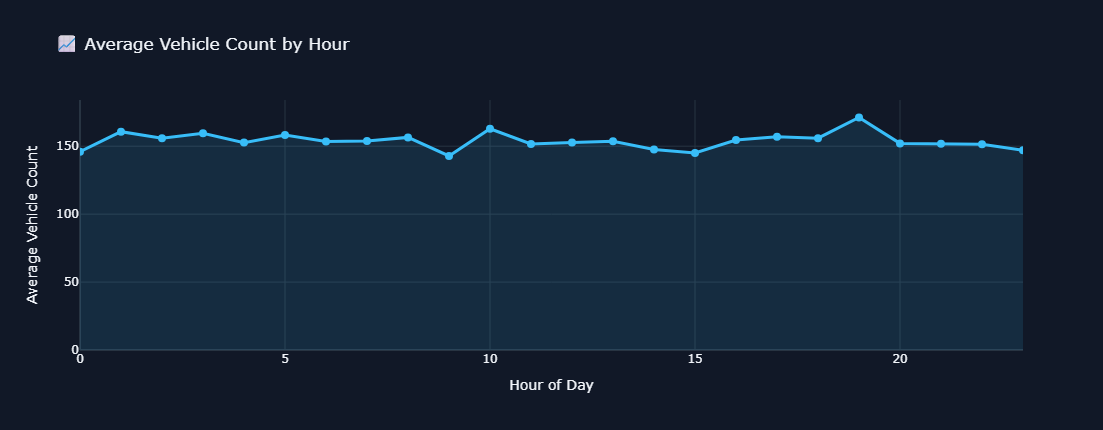

In [12]:
hourly = (
    df.groupby("hour", as_index=False)
    .agg(
        avg_speed=("traffic_speed_kmh", "mean"),
        avg_vehicles=("vehicle_count", "mean"),
        avg_occupancy=("road_occupancy_pct", "mean")
    )
    .sort_values("hour")
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=hourly["hour"],
        y=hourly["avg_vehicles"],
        mode="lines+markers",
        name="Average Vehicles",
        line=dict(color="#38bdf8", width=3),
        marker=dict(size=8),
        fill="tozeroy",
        fillcolor="rgba(56,189,248,0.12)"
    )
)

fig.update_layout(
    title="📈 Average Vehicle Count by Hour",
    template="plotly_dark",
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    height=430,
    xaxis_title="Hour of Day",
    yaxis_title="Average Vehicle Count",
    hovermode="x unified"
)

fig.show()

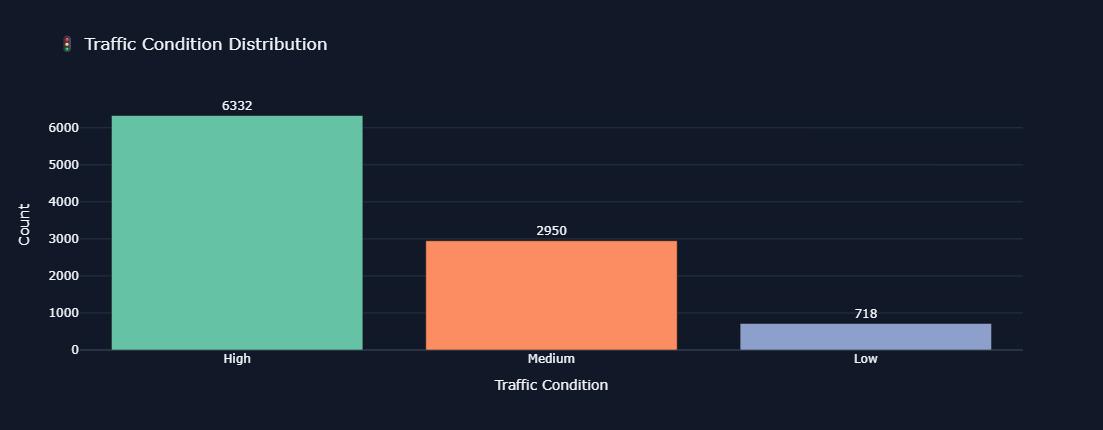

In [13]:
condition_data = (
    df["traffic_condition"]
    .value_counts()
    .reset_index()
)

condition_data.columns = ["Traffic Condition", "Count"]

fig = px.bar(
    condition_data,
    x="Traffic Condition",
    y="Count",
    color="Traffic Condition",
    text="Count",
    title="🚦 Traffic Condition Distribution",
    template="plotly_dark",
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_traces(textposition="outside")

fig.update_layout(
    height=430,
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    showlegend=False
)

fig.show()

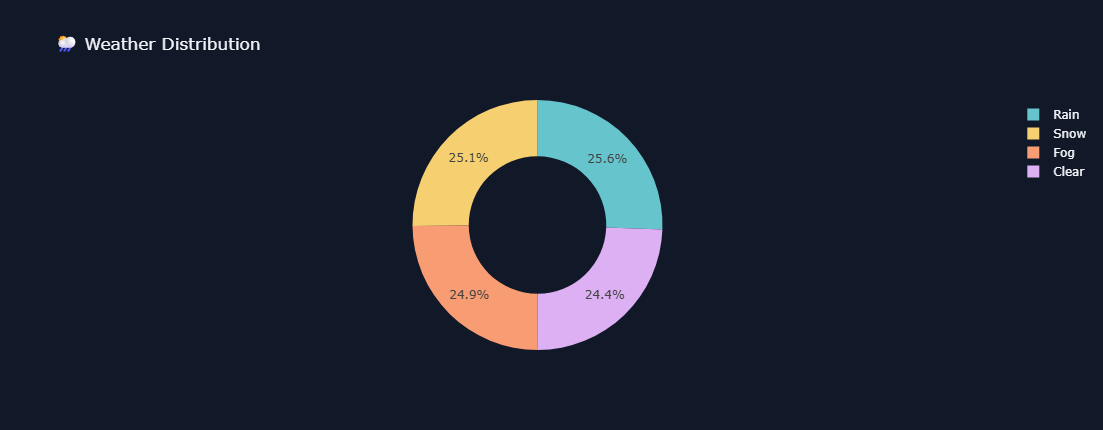

In [14]:
weather_data = (
    df["weather_condition"]
    .value_counts()
    .reset_index()
)

weather_data.columns = ["Weather", "Count"]

fig = px.pie(
    weather_data,
    names="Weather",
    values="Count",
    hole=0.55,
    title="🌦️ Weather Distribution",
    template="plotly_dark",
    color_discrete_sequence=px.colors.qualitative.Pastel
)

fig.update_layout(
    height=430,
    paper_bgcolor=CARD_BG
)

fig.show()

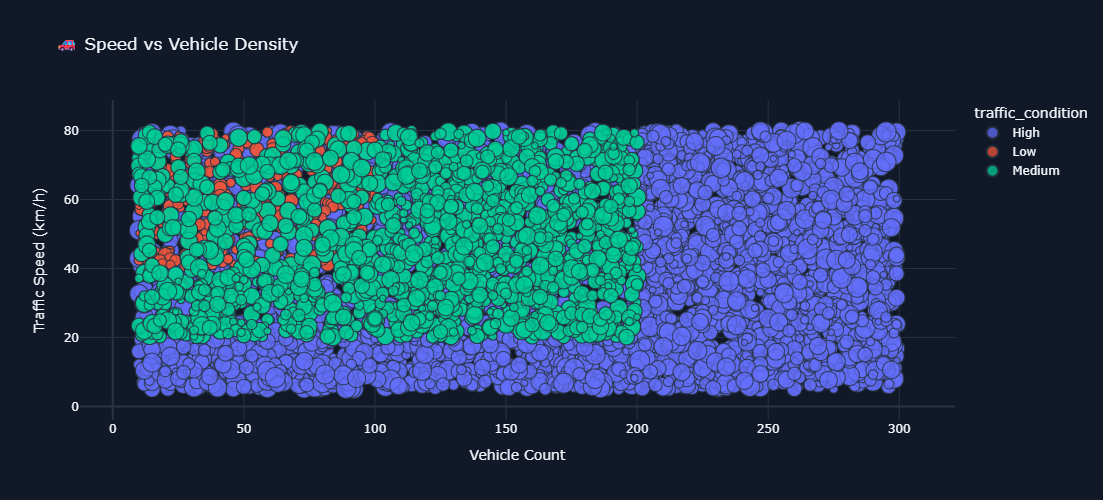

In [15]:
scatter_df = df.dropna(
    subset=[
        "vehicle_count",
        "traffic_speed_kmh",
        "road_occupancy_pct",
        "traffic_condition"
    ]
)

fig = px.scatter(
    scatter_df,
    x="vehicle_count",
    y="traffic_speed_kmh",
    color="traffic_condition",
    size="road_occupancy_pct",
    hover_data=[
        "weather_condition",
        "traffic_light_state",
        "latitude",
        "longitude"
    ],
    title="🚗 Speed vs Vehicle Density",
    template="plotly_dark",
    opacity=0.75
)

fig.update_layout(
    height=500,
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    xaxis_title="Vehicle Count",
    yaxis_title="Traffic Speed (km/h)"
)

fig.show()

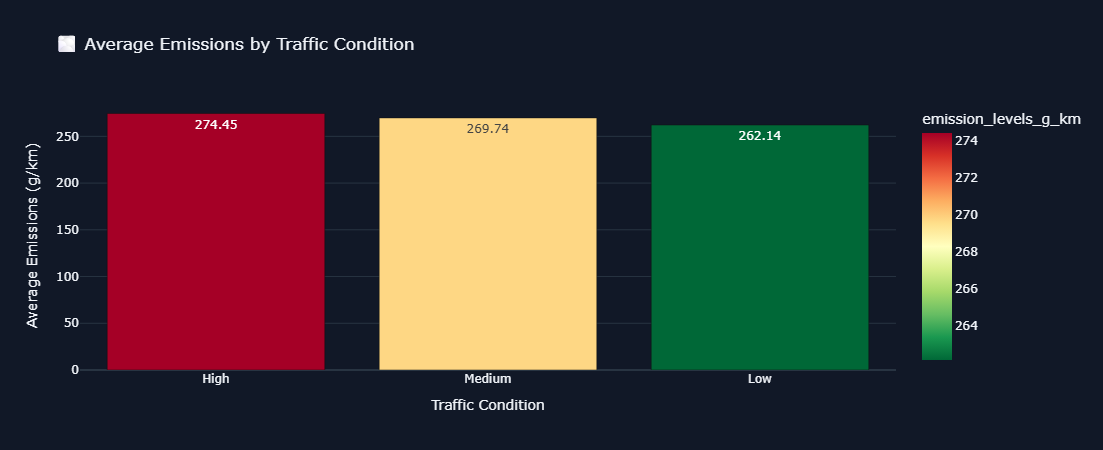

In [16]:
emission_data = (
    df.groupby("traffic_condition", as_index=False)
    ["emission_levels_g_km"]
    .mean()
    .sort_values("emission_levels_g_km", ascending=False)
)

fig = px.bar(
    emission_data,
    x="traffic_condition",
    y="emission_levels_g_km",
    color="emission_levels_g_km",
    text_auto=".2f",
    title="🌫️ Average Emissions by Traffic Condition",
    template="plotly_dark",
    color_continuous_scale="RdYlGn_r"
)

fig.update_layout(
    height=450,
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    xaxis_title="Traffic Condition",
    yaxis_title="Average Emissions (g/km)"
)

fig.show()

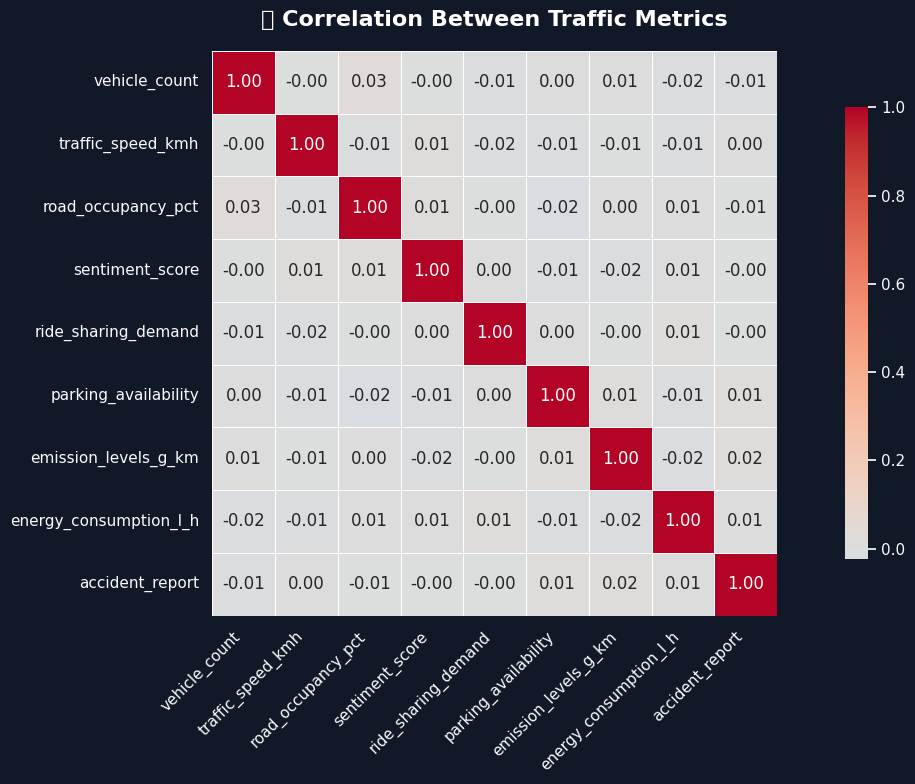

In [17]:
numeric_columns = [
    "vehicle_count",
    "traffic_speed_kmh",
    "road_occupancy_pct",
    "sentiment_score",
    "ride_sharing_demand",
    "parking_availability",
    "emission_levels_g_km",
    "energy_consumption_l_h",
    "accident_report"
]

corr = df[numeric_columns].corr()

plt.figure(figsize=(14, 8))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)

ax.set_title(
    "🔥 Correlation Between Traffic Metrics",
    fontsize=16,
    fontweight="bold",
    pad=18,
    color="white"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

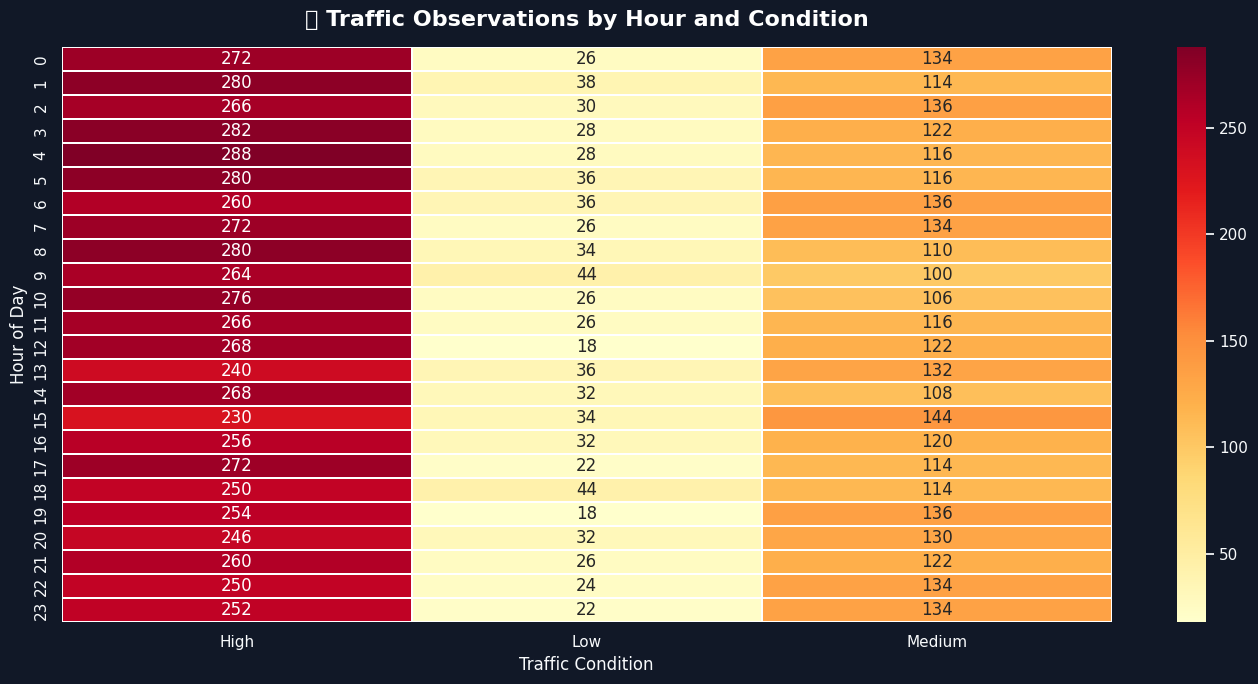

In [18]:
hour_condition = pd.crosstab(
    df["hour"],
    df["traffic_condition"]
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    hour_condition,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    linewidths=0.3
)

plt.title(
    "🕒 Traffic Observations by Hour and Condition",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="white"
)

plt.xlabel("Traffic Condition")
plt.ylabel("Hour of Day")

plt.tight_layout()
plt.show()

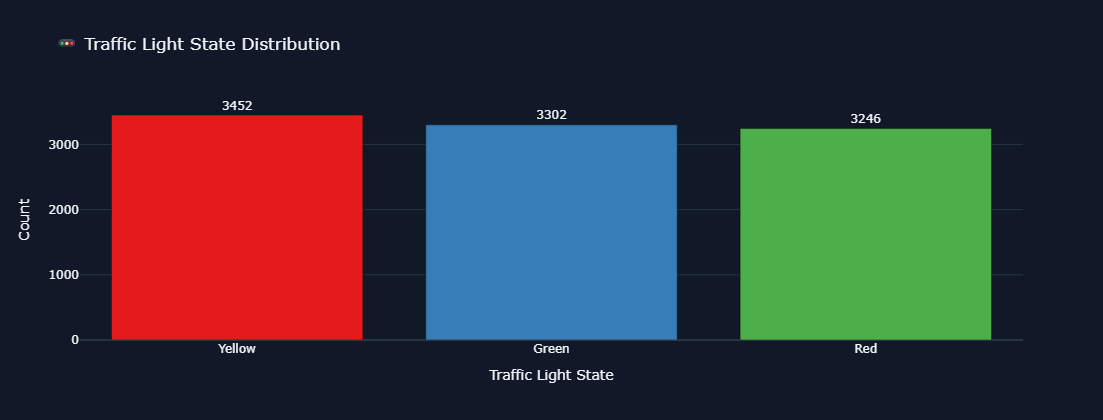

In [19]:
light_data = (
    df["traffic_light_state"]
    .value_counts()
    .reset_index()
)

light_data.columns = ["Traffic Light State", "Count"]

fig = px.bar(
    light_data,
    x="Traffic Light State",
    y="Count",
    color="Traffic Light State",
    text="Count",
    title="🚥 Traffic Light State Distribution",
    template="plotly_dark",
    color_discrete_sequence=px.colors.qualitative.Set1
)

fig.update_traces(textposition="outside")

fig.update_layout(
    height=420,
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    showlegend=False
)

fig.show()

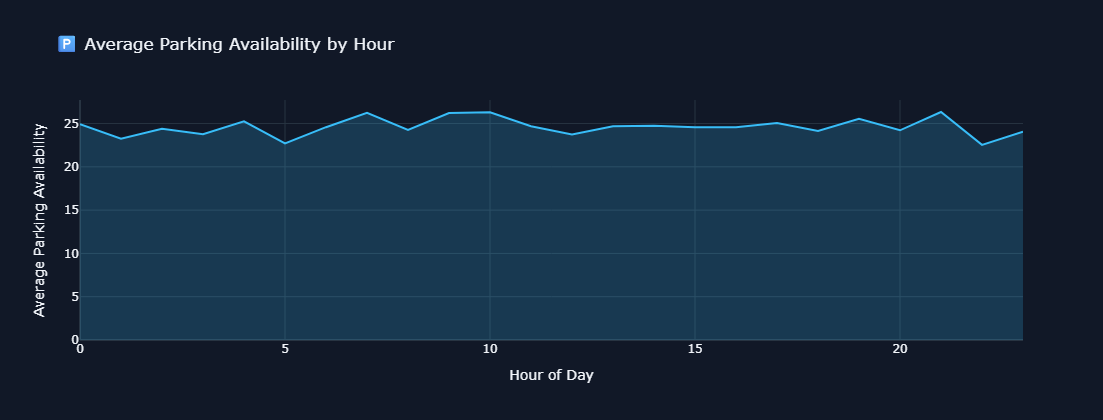

In [20]:
parking_data = (
    df.groupby("hour", as_index=False)
    ["parking_availability"]
    .mean()
    .sort_values("hour")
)

fig = px.area(
    parking_data,
    x="hour",
    y="parking_availability",
    title="🅿️ Average Parking Availability by Hour",
    template="plotly_dark"
)

fig.update_traces(
    line_color="#38bdf8",
    fillcolor="rgba(56,189,248,0.20)"
)

fig.update_layout(
    height=420,
    paper_bgcolor=CARD_BG,
    plot_bgcolor=CARD_BG,
    xaxis_title="Hour of Day",
    yaxis_title="Average Parking Availability"
)

fig.show()

In [21]:
summary = (
    df.groupby("traffic_condition", dropna=False)
    .agg(
        Records=("id", "count"),
        Avg_Vehicles=("vehicle_count", "mean"),
        Avg_Speed=("traffic_speed_kmh", "mean"),
        Avg_Occupancy=("road_occupancy_pct", "mean"),
        Avg_Emission=("emission_levels_g_km", "mean"),
        Accidents=("accident_report", "sum")
    )
    .reset_index()
)

summary["Avg_Vehicles"] = summary["Avg_Vehicles"].round(2)
summary["Avg_Speed"] = summary["Avg_Speed"].round(2)
summary["Avg_Occupancy"] = summary["Avg_Occupancy"].round(2)
summary["Avg_Emission"] = summary["Avg_Emission"].round(2)

display(
    summary.style
    .format({
        "Avg_Vehicles": "{:.2f}",
        "Avg_Speed": "{:.2f}",
        "Avg_Occupancy": "{:.2f}",
        "Avg_Emission": "{:.2f}",
        "Accidents": "{:.0f}"
    })
    .background_gradient(
        subset=["Avg_Vehicles", "Avg_Occupancy", "Avg_Emission"],
        cmap="YlOrRd"
    )
    .set_caption("Traffic Analytics Summary")
)

,traffic_condition,Records,Avg_Vehicles,Avg_Speed,Avg_Occupancy,Avg_Emission,Accidents
0,High,6332,182.49,37.87,60.68,274.45,960
1,Low,718,53.39,59.88,29.54,262.14,0
2,Medium,2950,117.06,46.90,48.15,269.74,0


In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

condition_options = sorted(
    df["traffic_condition"].dropna().unique().tolist()
)

weather_options = sorted(
    df["weather_condition"].dropna().unique().tolist()
)

signal_options = sorted(
    df["traffic_light_state"].dropna().unique().tolist()
)

min_speed = float(df["traffic_speed_kmh"].min())
max_speed = float(df["traffic_speed_kmh"].max())

condition_filter = widgets.SelectMultiple(
    options=condition_options,
    value=tuple(condition_options),
    description="Condition:",
    layout=widgets.Layout(width="320px", height="110px")
)

weather_filter = widgets.SelectMultiple(
    options=weather_options,
    value=tuple(weather_options),
    description="Weather:",
    layout=widgets.Layout(width="320px", height="110px")
)

signal_filter = widgets.SelectMultiple(
    options=signal_options,
    value=tuple(signal_options),
    description="Traffic Light:",
    layout=widgets.Layout(width="320px", height="110px")
)

speed_filter = widgets.FloatRangeSlider(
    value=(min_speed, max_speed),
    min=min_speed,
    max=max_speed,
    step=max((max_speed - min_speed) / 100, 0.1),
    description="Speed:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="450px")
)

apply_button = widgets.Button(
    description="Apply Filters",
    button_style="primary",
    icon="filter"
)

output = widgets.Output()

display(condition_filter)
display(weather_filter)
display(signal_filter)
display(speed_filter)
display(apply_button)
display(output)

SelectMultiple(description='Condition:', index=(0, 1, 2), layout=Layout(height='110px', width='320px'), option…

SelectMultiple(description='Weather:', index=(0, 1, 2, 3), layout=Layout(height='110px', width='320px'), optio…

SelectMultiple(description='Traffic Light:', index=(0, 1, 2), layout=Layout(height='110px', width='320px'), op…

FloatRangeSlider(value=(5.003, 79.998), continuous_update=False, description='Speed:', layout=Layout(width='45…

Button(button_style='primary', description='Apply Filters', icon='filter', style=ButtonStyle())

Output()

In [24]:
def apply_filters(button=None):

    with output:
        clear_output(wait=True)

        filtered = df[
            df["traffic_condition"].isin(condition_filter.value)
            & df["weather_condition"].isin(weather_filter.value)
            & df["traffic_light_state"].isin(signal_filter.value)
            & df["traffic_speed_kmh"].between(
                speed_filter.value[0],
                speed_filter.value[1]
            )
        ].copy()

        if filtered.empty:
            print("No records match the selected filters.")
            return

        print("FILTERED TRAFFIC ANALYTICS")
        print("=" * 50)

        print("Total Records:", len(filtered))

        print(
            "Average Vehicles:",
            round(filtered["vehicle_count"].mean(), 2)
        )

        print(
            "Average Speed:",
            round(filtered["traffic_speed_kmh"].mean(), 2),
            "km/h"
        )

        print(
            "Average Road Occupancy:",
            round(filtered["road_occupancy_pct"].mean(), 2),
            "%"
        )

        print(
            "Accident Reports:",
            int(filtered["accident_report"].sum())
        )

        # Traffic condition graph
        condition_counts = (
            filtered["traffic_condition"]
            .value_counts()
            .reset_index()
        )

        condition_counts.columns = ["Condition", "Count"]

        fig = px.bar(
            condition_counts,
            x="Condition",
            y="Count",
            color="Condition",
            text="Count",
            title="Filtered Traffic Conditions",
            template="plotly_dark"
        )

        fig.update_layout(
            paper_bgcolor=CARD_BG,
            plot_bgcolor=CARD_BG,
            showlegend=False
        )

        fig.show()

        # Hourly vehicle trend
        hourly_filtered = (
            filtered.groupby("hour", as_index=False)
            ["vehicle_count"]
            .mean()
        )

        fig2 = px.line(
            hourly_filtered,
            x="hour",
            y="vehicle_count",
            markers=True,
            title="Filtered Average Vehicle Count by Hour",
            template="plotly_dark"
        )

        fig2.update_layout(
            paper_bgcolor=CARD_BG,
            plot_bgcolor=CARD_BG,
            xaxis_title="Hour",
            yaxis_title="Average Vehicles"
        )

        fig2.show()

        # Summary table
        filtered_summary = (
            filtered.groupby("traffic_condition")
            .agg(
                Records=("id", "count"),
                Avg_Vehicles=("vehicle_count", "mean"),
                Avg_Speed=("traffic_speed_kmh", "mean"),
                Avg_Emission=("emission_levels_g_km", "mean")
            )
            .round(2)
            .reset_index()
        )

        display(filtered_summary)


apply_button.on_click(apply_filters)

# Show initial results
apply_filters()

In [25]:
display(HTML("""
<div style="
    background:linear-gradient(135deg,#111827,#172033);
    border:1px solid #263449;
    border-radius:16px;
    padding:22px;
    text-align:center;
">
    <h2 style="color:#f8fafc;">
        🚦 TrafficIQ Analytics Completed
    </h2>
    <p style="color:#94a3b8;">
        Built with Python, Pandas, MySQL, Plotly, Seaborn and Matplotlib.
    </p>
    <p style="color:#38bdf8;">
        Traffic Monitoring • Mobility Analytics • Environmental Insights
    </p>
</div>
"""))